# EnergyWatch AI — Entrenamiento de DBSCAN sobre consumo eléctrico real

**Problema:** detectar si el consumo eléctrico de un hogar (ventana de 30 min) corresponde a un patrón habitual o a una combinación atípica.
**Algoritmo:** DBSCAN (clustering basado en densidad, no supervisado). **Dataset:** UCI *Individual Household Electric Power Consumption* (2.075.259 mediciones por minuto, CC BY 4.0).
**Métrica del modelo:** Silhouette (excluyendo ruido) + porcentaje de ruido; mínimo exigido: Silhouette > 0.4.

Contenido: 1) carga y exploración · 2) EDA · 3) preprocesamiento y división train/test · 4) entrenamiento · 5) evaluación · 6) serialización y prueba.

In [1]:
import os, sys, json
from pathlib import Path
# El notebook debe ejecutarse desde la raíz del repositorio; si se abre desde notebooks/ se corrige la ruta.
if Path.cwd().name == 'notebooks': os.chdir('..')
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from src.preprocessing import FEATURES, download_dataset, load_windows, transform_features
from src.train import split_windows, train
from src.predict import analyze_records
pd.set_option('display.width', 140)

## 1. Carga y exploración de datos
Se descarga el archivo oficial (si no existe) y se inspecciona el dataset crudo, minuto a minuto.

In [2]:
path = download_dataset()
raw = pd.read_csv(path, sep=';', na_values=['?', ''], low_memory=False)
print('Registros originales:', len(raw), '| columnas:', list(raw.columns))
raw.info()
display(raw.head())
display(raw[FEATURES].describe().T)

Registros originales: 2075259 | columnas: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049280.0,1.091615,1.057294,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049280.0,0.123714,0.112722,0.000,0.048,0.100,0.194,1.390
Voltage,2049280.0,240.839858,3.239987,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049280.0,4.627759,4.444396,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049280.0,1.121923,6.153031,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049280.0,1.298520,5.822026,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049280.0,6.458447,8.437154,0.000,0.000,1.000,17.000,31.000


## 2. Análisis exploratorio (EDA)
### 2.1 Valores nulos
Los faltantes vienen marcados con `?` en el archivo original. No se imputan: las ventanas con menos del 80 % de cobertura se descartan.

In [3]:
missing = raw[FEATURES].isna().mean().mul(100).round(2)
print('% de valores faltantes por variable (crudo):'); display(missing.to_frame('% nulos'))
windows = load_windows(path)
print('Ventanas de 30 min válidas:', len(windows), 'de', len(raw)//30, 'posibles')
print('Nulos tras agregación:', int(windows[FEATURES].isna().sum().sum()))
display(windows.head())

% de valores faltantes por variable (crudo):


,% nulos
Global_active_power,1.25
Global_reactive_power,1.25
Voltage,1.25
Global_intensity,1.25
Sub_metering_1,1.25
Sub_metering_2,1.25
Sub_metering_3,1.25


Ventanas de 30 min válidas: 68304 de 69175 posibles
Nulos tras agregación: 0


,timestamp,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:30:00,4.150000,0.178000,234.699333,17.780000,0.0,0.366667,16.866667
1,2006-12-16 18:00:00,3.944800,0.084867,235.184667,16.966667,0.0,11.400000,16.966667
2,2006-12-16 18:30:00,3.319600,0.075200,233.975667,14.233333,0.0,2.033333,16.766667
3,2006-12-16 19:00:00,3.464400,0.049800,233.754000,14.746667,0.0,1.833333,16.766667
4,2006-12-16 19:30:00,3.336067,0.120667,232.711000,14.260000,0.0,1.033333,16.600000


### 2.2 Distribuciones y outliers
Las variables de potencia están muy sesgadas a la derecha (picos de consumo): por eso se aplica `log1p` antes de escalar.

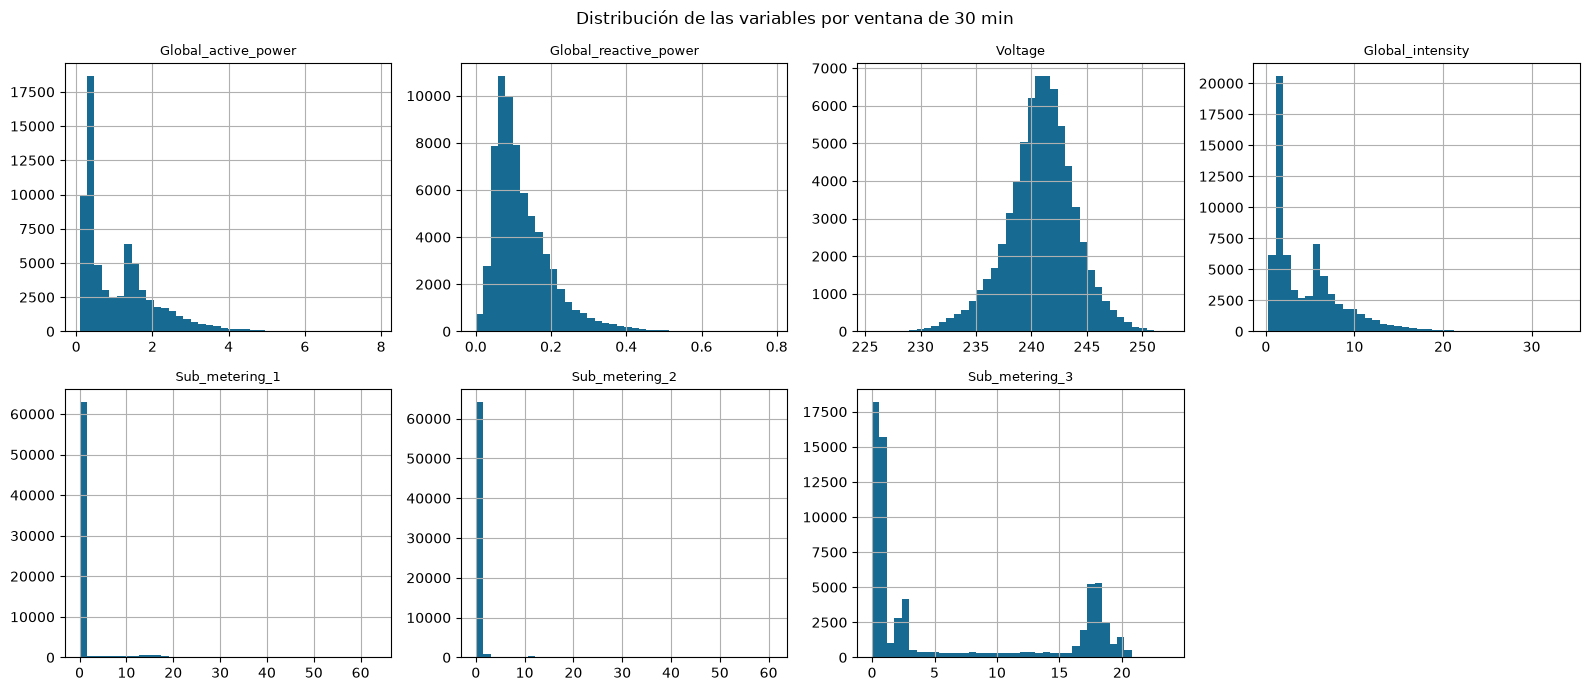

% de outliers por regla IQR (1.5):


,% outliers
Global_active_power,2.8
Global_reactive_power,3.9
Voltage,2.8
Global_intensity,3.1
Sub_metering_1,11.8
Sub_metering_2,5.4
Sub_metering_3,0.0


In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), FEATURES):
    windows[col].hist(ax=ax, bins=40, color='#176B93'); ax.set_title(col, fontsize=9)
axes.ravel()[-1].axis('off')
plt.suptitle('Distribución de las variables por ventana de 30 min'); plt.tight_layout(); plt.show()

q1, q3 = windows[FEATURES].quantile(.25), windows[FEATURES].quantile(.75)
iqr = q3 - q1
outliers = ((windows[FEATURES] < q1 - 1.5*iqr) | (windows[FEATURES] > q3 + 1.5*iqr)).mean().mul(100).round(1)
print('% de outliers por regla IQR (1.5):'); display(outliers.to_frame('% outliers'))

### 2.3 Correlaciones

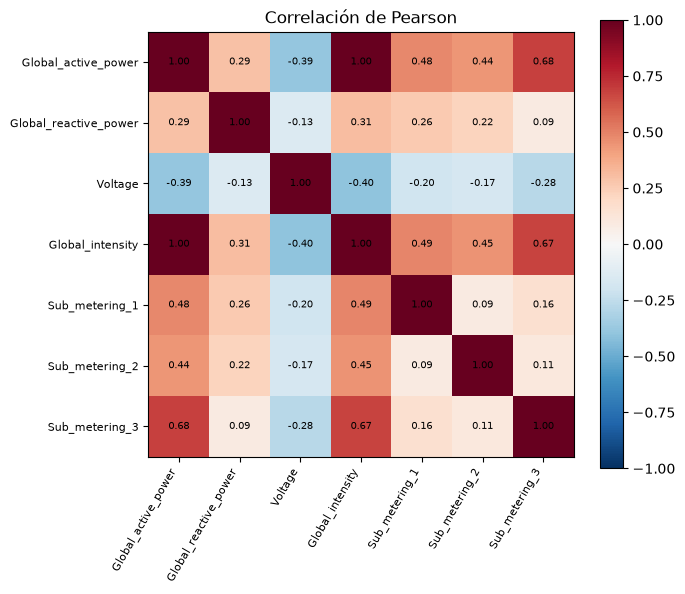

In [5]:
corr = windows[FEATURES].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES, fontsize=8)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)): ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); plt.title('Correlación de Pearson'); plt.tight_layout(); plt.show()

### 2.4 Comportamiento en el tiempo

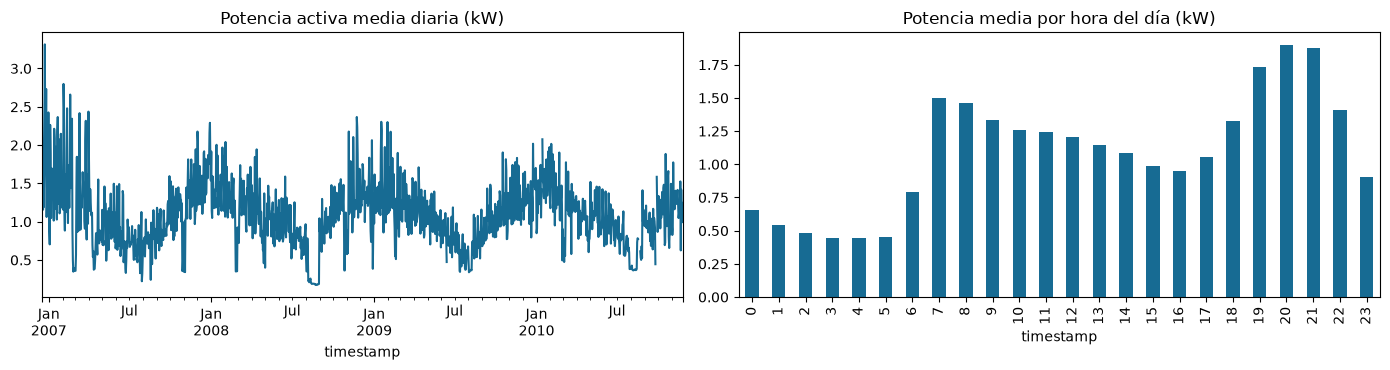

In [6]:
daily = windows.set_index('timestamp')['Global_active_power'].resample('D').mean()
hourly = windows.groupby(windows['timestamp'].dt.hour)['Global_active_power'].mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
daily.plot(ax=ax[0], color='#176B93'); ax[0].set_title('Potencia activa media diaria (kW)')
hourly.plot(kind='bar', ax=ax[1], color='#176B93'); ax[1].set_title('Potencia media por hora del día (kW)')
plt.tight_layout(); plt.show()

## 3. Preprocesamiento y división train/test
- **Limpieza:** ventanas de 30 min con ≥ 80 % de mediciones válidas; sin imputación.
- **Transformación:** `log1p` en potencias, corriente y submedidores; `RobustScaler` (resistente a outliers) ajustado **solo con entrenamiento**.
- **División cronológica 80/20:** se entrena con el pasado y se evalúa con el futuro, sin mezclar. No hay variables categóricas que codificar.
- **Muestreo reproducible** (semillas 42 y 43) por costo computacional de DBSCAN.

In [7]:
train_pool, test_pool, train_df, test_df = split_windows(windows)
print(f'Entrenamiento: {len(train_pool)} ventanas ({train_pool.timestamp.min():%Y-%m-%d} → {train_pool.timestamp.max():%Y-%m-%d}), muestra usada: {len(train_df)}')
print(f'Prueba:        {len(test_pool)} ventanas ({test_pool.timestamp.min():%Y-%m-%d} → {test_pool.timestamp.max():%Y-%m-%d}), muestra usada: {len(test_df)}')
X_train, scaler = transform_features(train_df)
X_test, _ = transform_features(test_df, scaler)
print('Matriz de entrenamiento escalada:', X_train.shape)

Entrenamiento: 54643 ventanas (2006-12-16 → 2010-02-05), muestra usada: 3500
Prueba:        13661 ventanas (2010-02-05 → 2010-11-26), muestra usada: 1200
Matriz de entrenamiento escalada: (3500, 7)


## 4. Entrenamiento de DBSCAN
DBSCAN necesita `eps` (radio) y `min_samples` (densidad mínima). Se evalúa una malla de 18 combinaciones y se elige la de mayor `Silhouette − 0.2·ruido`, exigiendo ≥ 2 clústeres, ≤ 45 % de ruido y grupos de al menos 1 % de los datos (evita soluciones triviales).
Primero, el gráfico de distancias al k-ésimo vecino (con k = `min_samples`) ayuda a justificar el rango de `eps`.

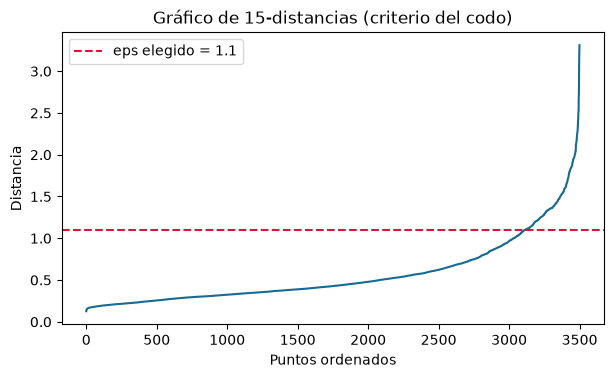

In [8]:
k = 15
dist, _ = NearestNeighbors(n_neighbors=k).fit(X_train).kneighbors(X_train)
plt.figure(figsize=(7, 3.8)); plt.plot(np.sort(dist[:, -1]), color='#176B93')
plt.axhline(1.1, color='crimson', ls='--', label='eps elegido = 1.1'); plt.legend()
plt.title(f'Gráfico de {k}-distancias (criterio del codo)'); plt.xlabel('Puntos ordenados'); plt.ylabel('Distancia'); plt.show()

In [9]:
metadata = train()   # busca hiperparámetros, evalúa y serializa models/modelo.joblib, metadata.json y replay_test.csv
search = pd.DataFrame(metadata['all_search_results'])
display(search.sort_values('silhouette_no_noise', ascending=False).head(8))

{
  "dataset": "UCI Individual Household Electric Power Consumption",
  "source": "https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption",
  "total_windows": 68304,
  "train_pool": 54643,
  "test_pool": 13661,
  "train_used": 3500,
  "test_used": 1200,
  "train_metrics": {
    "eps": 1.1,
    "min_samples": 15,
    "silhouette_no_noise": 0.573167828361033,
    "noise_ratio": 0.05142857142857143,
    "n_clusters": 2,
    "min_cluster_size": 87
  },
  "test_metrics": {
    "silhouette_no_noise": 0.6178482016288843,
    "noise_ratio": 0.029166666666666667,
    "n_clusters": 2,
    "min_cluster_size": 20
  },
  "parameters": {
    "eps": 1.1,
    "min_samples": 15
  },
  "thresholds": {
    "power_p95": 3.066846666666666,
    "power_p05": 0.2054
  },
  "method": "core nearest neighbor assignment, held-out chronological split",
  "warning": "Silhouette excluye ruido; leer junto con noise_ratio. Puntuacion de test es solo descriptiva."
}


,eps,min_samples,silhouette_no_noise,noise_ratio,n_clusters,min_cluster_size
15,1.40,8,0.619724,0.011143,2,8
14,1.10,25,0.589282,0.083143,2,29
13,1.10,15,0.573168,0.051429,2,87
9,0.90,8,0.572030,0.076286,3,21
7,0.70,15,0.490229,0.171143,2,15
11,0.90,25,0.476726,0.132000,2,45
10,0.90,15,0.463257,0.104571,3,31
2,0.35,25,0.459402,0.592000,2,336


## 5. Evaluación

In [10]:
info_train, info_test = metadata['train_metrics'], metadata['test_metrics']
table = pd.DataFrame({'Entrenamiento': info_train, 'Prueba (futuro)': info_test}).T[['n_clusters', 'noise_ratio', 'silhouette_no_noise', 'min_cluster_size']]
table.columns = ['Clústeres', 'Ruido', 'Silhouette (sin ruido)', 'Tamaño mínimo de clúster']
display(table)
print('Parámetros elegidos:', metadata['parameters'])
print('Silhouette de prueba > 0.4:', info_test['silhouette_no_noise'] > 0.4)

,Clústeres,Ruido,Silhouette (sin ruido),Tamaño mínimo de clúster
Entrenamiento,2.0,0.051429,0.573168,87.0
Prueba (futuro),2.0,0.029167,0.617848,20.0


Parámetros elegidos: {'eps': 1.1, 'min_samples': 15}
Silhouette de prueba > 0.4: True


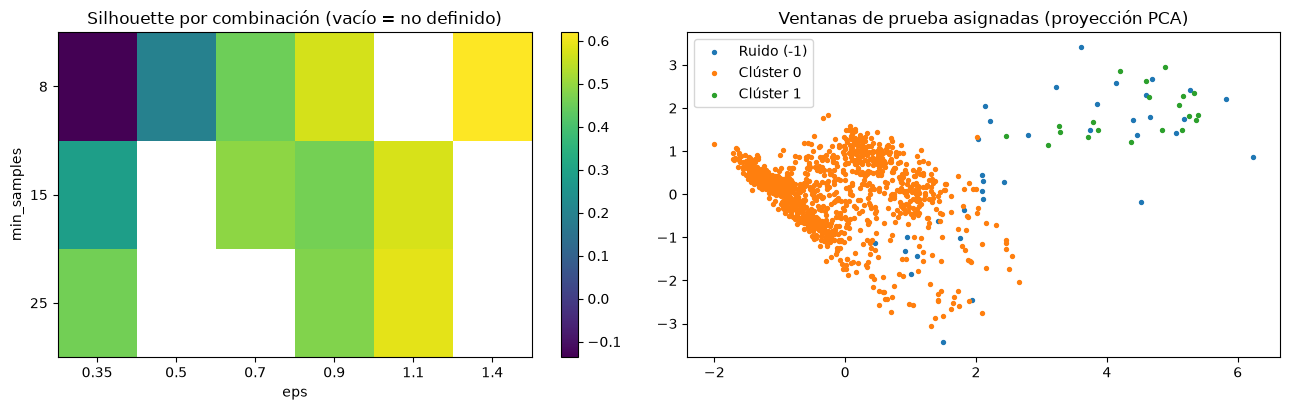

cluster
-1      35
 0    1145
 1      20


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
pivot = search.pivot(index='min_samples', columns='eps', values='silhouette_no_noise')
im = ax[0].imshow(pivot.values.astype(float), cmap='viridis', aspect='auto')
ax[0].set_xticks(range(len(pivot.columns))); ax[0].set_xticklabels(pivot.columns)
ax[0].set_yticks(range(len(pivot.index))); ax[0].set_yticklabels(pivot.index)
ax[0].set_xlabel('eps'); ax[0].set_ylabel('min_samples'); ax[0].set_title('Silhouette por combinación (vacío = no definido)'); plt.colorbar(im, ax=ax[0])

bundle = joblib.load('models/modelo.joblib')
assigned = analyze_records(test_df, bundle)
pca = PCA(n_components=2, random_state=0).fit(X_train)   # PCA solo para visualizar en 2D
Z = pca.transform(X_test)
for lab in sorted(assigned['cluster'].unique()):
    sel = (assigned['cluster'] == lab).to_numpy()
    ax[1].scatter(Z[sel, 0], Z[sel, 1], s=8, label='Ruido (-1)' if lab == -1 else f'Clúster {lab}')
ax[1].legend(); ax[1].set_title('Ventanas de prueba asignadas (proyección PCA)'); plt.tight_layout(); plt.show()
print(assigned['cluster'].value_counts().sort_index().to_string())

## 6. Serialización y prueba de carga
El artefacto `models/modelo.joblib` contiene escalador, puntos núcleo, etiquetas, `eps` y umbrales. Se vuelve a cargar y se predice con tres casos.

In [12]:
bundle = joblib.load('models/modelo.joblib')
print('Contenido del artefacto:', list(bundle))
casos = pd.DataFrame([
    [1.2, 0.12, 240, 5.0, 2, 0, 10],      # hogar con consumo moderado
    [5.5, 0.30, 240, 23.0, 20, 40, 90],   # varios aparatos de resistencia a la vez
    [0.3, 0.05, 240, 1.3, 0, 0, 1],       # consumo base de madrugada
], columns=FEATURES)
display(analyze_records(casos, bundle)[['Global_active_power', 'cluster', 'core_distance', 'power_status', 'alert']])

Contenido del artefacto: ['scaler', 'model', 'core_points', 'core_labels', 'eps', 'features', 'thresholds', 'window', 'version']


,Global_active_power,cluster,core_distance,power_status,alert
0,1.2,0,0.676575,Potencia dentro de referencias históricas,Patrón conocido
1,5.5,-1,3.378314,Potencia elevada frente a referencia histórica,Patrón atípico y potencia elevada
2,0.3,0,0.142650,Potencia dentro de referencias históricas,Patrón conocido


In [13]:
from IPython.display import Markdown
Markdown(f'''### Conclusiones
- DBSCAN encontró **{info_train["n_clusters"]} clústeres densos** con `eps={metadata["parameters"]["eps"]}` y `min_samples={metadata["parameters"]["min_samples"]}`.
- **Silhouette** (sin ruido): **{info_train["silhouette_no_noise"]:.3f}** en entrenamiento y **{info_test["silhouette_no_noise"]:.3f}** en la evaluación cronológica posterior, por encima del mínimo de 0.4.
- **Ruido** (combinaciones atípicas): {info_train["noise_ratio"]:.1%} en entrenamiento y {info_test["noise_ratio"]:.1%} en prueba.
- Silhouette excluye el ruido, por lo que se interpreta junto con su porcentaje. Los clústeres son densidades estadísticas, no categorías técnicas.
- **Limitación:** los datos son de una sola vivienda; los resultados en otros hogares son orientativos.''')

### Conclusiones
- DBSCAN encontró **2 clústeres densos** con `eps=1.1` y `min_samples=15`.
- **Silhouette** (sin ruido): **0.573** en entrenamiento y **0.618** en la evaluación cronológica posterior, por encima del mínimo de 0.4.
- **Ruido** (combinaciones atípicas): 5.1% en entrenamiento y 2.9% en prueba.
- Silhouette excluye el ruido, por lo que se interpreta junto con su porcentaje. Los clústeres son densidades estadísticas, no categorías técnicas.
- **Limitación:** los datos son de una sola vivienda; los resultados en otros hogares son orientativos.